# HW 9, Problem 3: Ensemble score filter (EnSF)

EnSF for the two HW 8 systems, one-layer Lorenz–96 ($K = 40$, $n = 40$) and two-layer Lorenz–96 ($K = 10$, $J = 2$, $n = 30$), with the same dimensions and state order. Everything about the physical experiment is loaded from the saved HW 8 data (`data/hw8_twin_*.npz`) and `src/da_models/hw8.py`; nothing is regenerated.

* **EnSF analysis:** `src/da_models/ensf.py` (`schedule`, `mixture_score`, `make_likelihood_score`, `reverse_sample`, `ensf_analysis`, `run_ensf`), written from Section 3 of the diffusion notes.
* **HW 9 settings:** `src/da_models/hw9.py` (center $c$, $N_e$, $L$, $\epsilon_\alpha$, $\epsilon_\beta$, random streams).
* **Reused from HW 8:** the physical solver and ensemble propagator, the stochastic EnKF (`enkf.py`), the EKF (`ekf.py`), and the scaled diagnostics.

Ensembles are stored with one member per **column**, as in `enkf.py`; the class notebook stores members in rows, which is only a transpose.

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Markdown, display

from da_models import hw8, hw9
from da_models.assimilation import flatten
from da_models.ekf import run_ekf
from da_models.enkf import draw_initial_ensemble, run_enkf, enkf_analysis, ensemble_mean_cov
from da_models.ensf import schedule, reverse_sample, ensf_analysis, run_ensf

DATA_DIR = Path("../data")   # adjust if running in Colab
NAMES = ("l96", "l96_2layer")

# EnSF numerical settings (hw9.py); EPS_B can be set per model
NE = hw9.NE                  # 50
L_STEPS = hw9.L_STEPS        # 600
EPS_A = hw9.EPS_A            # 0.01
EPS_B = {name: hw9.EPS_B for name in NAMES}   # 0.01 for both models
REPLICATES = hw9.REPLICATES  # (0, 1, 2)

R_SHOW = 0                   # replicate shown in the time-series figures (fixed before running)
K_SHOW = 50                  # analysis time t_50 = 5.0 used for the detailed diagnostics in (e)
INCLUDE_EKF = True           # optional HW 8 EKF row in the tables
RUN_EPS_CHECK = True         # supplementary epsilon_beta check in (b); about 4 minutes

models = {name: hw9.load_model(name, DATA_DIR) for name in NAMES}
twins = {name: hw8.load_twin(name, DATA_DIR) for name in NAMES}
L_OBS, DT = hw8.L, hw8.DT_OBS
t_an = DT * np.arange(L_OBS + 1)          # t_0, ..., t_L
t_obs = t_an[1:]                          # t_1, ..., t_L

np.set_printoptions(precision=4, suppress=True, linewidth=110)
C = dict(truth="#0b0b0b", free="#8c8a85", obs="#eb6834",
         enkf="#1baf7a", ensf="#8e44ad", ekf="#2a78d6", fc="#b5b3ad")
REP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]      # replicates r = 0, 1, 2 (fixed order)
plt.rcParams.update({
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.2, "legend.frameon": False, "figure.dpi": 110,
})

def time_avg_rmse(rmse):
    # sqrt( L^{-1} sum_{k=1}^{L} RMSE_k^2 ); rmse[0] is the initial time and is excluded
    return np.sqrt(np.mean(rmse[1:] ** 2))

def add_diagnostics(o, mdl, tw):
    o["rmse"], o["spread"] = hw8.scaled_rmse_spread(o["mean_a"], tw["x_true"], mdl["D"], o["cov_a"])
    return o

def fmt_range(values, digits=3):
    v = np.asarray(values, dtype=float)
    return f"{v.mean():.{digits}f} [{v.min():.{digits}f}, {v.max():.{digits}f}]"

def sym(label):
    # "u1" -> "$u_{1}$", "v0,1" -> "$v_{0,1}$"
    return "$" + label[0] + "_{" + label[1:] + "}$"

FILTER_NAMES = {"enkf": "EnKF", "ensf": "EnSF"}

## (a) Controlled experiment

Reused unchanged from HW 8 for each model: the saved truth and observations, the model parameters, the physical solver (`solve_ivp`, RK45, `rtol = atol = 1e-9`), $H$ (every second $u_k$), $R = I_p$, the observation interval $\delta t = 0.1$ and horizon $T = 10$ ($L = 100$ analyses, no $y_0$), the prior $m_0^a = x_0^\dagger + 0.1D\mathbf 1$, $P_0^a = 0.01D^2$, the free forecast, and the fixed scales $D$. $Q_{k-1} = 0$: the forecast is the deterministic model, with no added model noise.

**Rescaled coordinates.** $u = D^{-1}(x - c)$ with the HW 8 $D$ and a fixed center $c$ chosen before assimilation: the climatological mean from the long free model run made in HW 5 / HW 8 Problem 1, pooled within each variable family exactly as $D$ pools the climatological variance (`hw9.state_center`). Under the climatology, $u$ then has mean $\approx 0$ and variance $\approx 1$ in every component, the scale of the artificial noise $N(0, I)$. Observations stay in their original units, so $R$ is unchanged and the likelihood score is
$$\nabla_z \log \ell_k(c + Dz) = (HD)^T R^{-1}\big[y_k - H(c + Dz)\big].$$

**Physical domain.** Lorenz–96 has no restricted state domain, so the HW 8 condition is that every state is finite. It is checked for the initial ensemble, every forecast, and every EnSF terminal ensemble before it is propagated (`run_ensf`, `admissible=finite_states`); a violation stops the run and is reported with its time.

In [2]:
rows = []
for name, mdl in models.items():
    tw = twins[name]
    meta = tw["meta"]
    # the saved HW 8 data must match the current settings exactly
    assert meta["params"] == {k: list(v) if isinstance(v, tuple) else v for k, v in mdl["params"].items()}
    for key in ("x0", "H", "R", "D", "m0", "P0"):
        assert np.array_equal(tw[key], mdl[key]), key
    assert meta["dt_obs"] == DT and meta["L"] == L_OBS and meta["solver"] == hw8.SOLVER
    fam = hw8.variable_families(name)
    p = mdl["H"].shape[0]
    first_obs = ", ".join(mdl["labels"][i] for i in mdl["observed"][:3])
    D_txt = ", ".join("%s: %.3f" % (f, mdl["D"][i[0]]) for f, i in fam.items())
    c_txt = ", ".join("%s: %.3f" % (f, mdl["c"][i[0]]) for f, i in fam.items())
    rows.append(f"| {mdl['title']} | {mdl['n']} | {p} ({first_obs}, ...) | $I_{{{p}}}$ | {D_txt} | {c_txt} |")
display(Markdown(
    f"Common: $\\delta t = {DT}$, $T = {hw8.T_FINAL:g}$, $L = {L_OBS}$ analyses, solver `solve_ivp` "
    f"{hw8.SOLVER['method']} (rtol = atol = {hw8.SOLVER['rtol']:g}), $Q = 0$, prior "
    f"$m_0^a = x_0^\\dagger + {hw8.PRIOR_SHIFT}D\\mathbf 1$, $P_0^a = {hw8.PRIOR_VAR}D^2$, data stream "
    f"`default_rng([513, 0, model])`.\n\n"
    "| Model | $n$ | observed $p$ | $R$ | $D$ (per family) | $c$ (per family) |\n|---|---|---|---|---|---|\n"
    + "\n".join(rows)))

for name, mdl in models.items():
    u_clim = (mdl["mu"] - mdl["c"]) / mdl["D"]
    var_clim = np.diag(mdl["B"]) / mdl["D"] ** 2
    u_prior = hw9.to_u(mdl["m0"], mdl)
    print(f"{mdl['title']}: climatology in u: |mean| <= {np.abs(u_clim).max():.3f}, variance "
          f"{var_clim.min():.3f} to {var_clim.max():.3f};  prior mean m0 in u: {u_prior.min():.2f} to {u_prior.max():.2f}")

Common: $\delta t = 0.1$, $T = 10$, $L = 100$ analyses, solver `solve_ivp` RK45 (rtol = atol = 1e-09), $Q = 0$, prior $m_0^a = x_0^\dagger + 0.1D\mathbf 1$, $P_0^a = 0.01D^2$, data stream `default_rng([513, 0, model])`.

| Model | $n$ | observed $p$ | $R$ | $D$ (per family) | $c$ (per family) |
|---|---|---|---|---|---|
| One-layer Lorenz-96 | 40 | 20 (u0, u2, u4, ...) | $I_{20}$ | u: 3.639 | u: 2.339 |
| Two-layer Lorenz-96 (K = 10, J = 2) | 30 | 5 (u0, u2, u4, ...) | $I_{5}$ | u: 3.025, v1: 0.952, v2: 0.648 | u: 2.391, v1: -3.716, v2: -1.486 |

One-layer Lorenz-96: climatology in u: |mean| <= 0.018, variance 0.974 to 1.021;  prior mean m0 in u: -2.38 to 1.80
Two-layer Lorenz-96 (K = 10, J = 2): climatology in u: |mean| <= 0.045, variance 0.950 to 1.062;  prior mean m0 in u: -1.64 to 1.64


## (b) EnSF analysis routine

At each observation time $t_k$ (`run_ensf`, `ensf_analysis`):

1. **Forecast once in physical time.** All analysis members are advanced with the HW 8 ensemble propagator (one stacked `solve_ivp` call per window, $Q = 0$). The forecast members are then held fixed, and the physical ODE is not integrated inside the reverse loop.
2. **Rescale.** $u_k^{f,(i)} = D^{-1}(x_k^{f,(i)} - c)$; the mixture cloud centers at artificial time $\tau$ are $a_\tau u_k^{f,(i)}$.
3. **Start new positions** $z^{(i)}_1 \sim N(0, I_n)$, $i = 1, \dots, N_e$, from the EnSF stream `default_rng([513, 4, model, Ne, r])`.
4. **Reverse loop**, $\tau = 1, 1 - \Delta\tau, \dots, \Delta\tau$ with $\Delta\tau = 1/L$, coefficients at $\tau_{\text{old}}$:
   * regularized schedule $a_\tau = 1 - \tau(1 - \epsilon_\alpha)$, $v_\tau = \epsilon_\beta + \tau(1 - \epsilon_\beta)$, $b_\tau = -(1 - \epsilon_\alpha)/a_\tau$, $g_\tau^2 = (1 - \epsilon_\beta) - 2b_\tau v_\tau$;
   * local weights $\rho_i(z, \tau) \propto \exp\!\big[-\lVert z - a_\tau u_k^{f,(i)}\rVert^2/(2v_\tau)\big]$, computed after subtracting the largest log weight, and the mixture score $\hat s^f(z, \tau) = \big[a_\tau\sum_i \rho_i u_k^{f,(i)} - z\big]/v_\tau$, recomputed at every step;
   * guided score $\tilde s(z, \tau) = \hat s^f(z, \tau) + (1 - \tau)\nabla_z\log\ell_k(c + Dz)$, with $y_k$ fixed (no perturbed observations);
   * Euler–Maruyama step $z \leftarrow z + \big[-b_\tau z + g_\tau^2\tilde s(z, \tau)\big]\Delta\tau + g_\tau\sqrt{\Delta\tau}\,\xi$ with fresh $\xi \sim N(0, I_n)$ for every position and step.
5. **Return to physical units:** $x_k^{a,(i)} = c + Dz_0^{(i)}$, check the domain, and propagate.

The likelihood score is affine in $z$, so it is precomputed once per analysis as $\beta - Az$ with $A = (HD)^TR^{-1}HD$ and $\beta = (HD)^TR^{-1}(y_k - Hc)$, using Cholesky solves with $R$ (no explicit inverse).

### Checks of the reverse sampler

1. **Known answer, scalar.** Forecast $N(0, 1)$, $y = 1$, $R = 1$: the exact analysis is $N(1/2, 1/2)$. Reverse sampling with the **exact** noisy analysis score $-(z - a_\tau/2)/(a_\tau^2/2 + v_\tau)$ should end at $N(1/2, 1/2 + \epsilon_\beta)$. The **guided** rule with the exact forecast score $-z/(a_\tau^2 + v_\tau)$ gives a different answer, and changing $L$ should not remove the difference (200,000 samples each).
2. **No observation, full dimension.** With the likelihood removed ($H = 0$), the terminal samples should reproduce the forecast mixture: mean equal to the member mean, covariance $\frac{N_e - 1}{N_e}P^f_u + \epsilon_\beta I$ in $u$ units. Forecast: the prior ensemble ($N_e = 50$) advanced one window; 4000 samples. The Monte Carlo reference for the relative covariance error is $\sqrt{(\operatorname{tr}(C)^2 + \lVert C\rVert_F^2)/N_s}\,/\,\lVert C\rVert_F$ for $N_s$ independent Gaussian samples.
3. **Linear–Gaussian, full dimension, with observations.** A synthetic Gaussian forecast in $u$ units with $n = 40$, cyclic correlations, and standard deviation 0.15 (about the one-layer forecast spread), every second component observed with $R_u = I/13.2$ (the one-layer $R = I$ expressed in $u$ units, $D = 3.64$). The Kalman analysis $N(m^a, P^a)$ is known, so the reference for the terminal EnSF samples is $N(m^a, P^a + \epsilon_\beta I)$, as in check 1. EnSF uses forecast ensembles of $N_e = 50$ and $500$ drawn from the Gaussian forecast.

In [3]:
rng = np.random.default_rng(2026)
NS_CHECK = 200_000
exact = lambda Z, tau, a, v: -(Z - a / 2) / (a * a / 2 + v)
guided = lambda Z, tau, a, v: -Z / (a * a + v) + (1 - tau) * (1.0 - Z)

Z0 = reverse_sample(rng.standard_normal((1, NS_CHECK)), exact, L_STEPS, EPS_A, hw9.EPS_B, rng)
print(f"exact score,  L = {L_STEPS}: mean {Z0.mean():.4f}, variance {Z0.var():.4f}   "
      f"(target N(0.5, {0.5 + hw9.EPS_B:.2f}); Monte Carlo sd of the mean {np.sqrt(0.51 / NS_CHECK):.4f})")
for L in (150, 600, 2400):
    Z0 = reverse_sample(rng.standard_normal((1, NS_CHECK)), guided, L, EPS_A, hw9.EPS_B, rng)
    print(f"guided score, L = {L:4d}: mean {Z0.mean():.4f}, variance {Z0.var():.4f}")

print()
for name, mdl in models.items():
    E0 = draw_initial_ensemble(mdl["m0"], mdl["P0"], NE, hw8.rng_init(name, NE, 0))
    Ef = mdl["propagate_ens"](E0)[-1]
    n = mdl["n"]
    Ea, info = ensf_analysis(Ef, np.zeros(1), np.zeros((1, n)), np.eye(1), mdl["c"], mdl["D"],
                             np.random.default_rng([2026, n]), L_STEPS, EPS_A, EPS_B[name], n_samples=4000)
    U, Ua = hw9.to_u(Ef, mdl), hw9.to_u(Ea, mdl)
    C_mix = np.cov(U, bias=True) + EPS_B[name] * np.eye(n)
    C_smp = np.cov(Ua)
    print(f"{mdl['title']}, no observation: max |sample mean - member mean| = {np.abs(Ua.mean(1) - U.mean(1)).max():.4f} "
          f"(u units);  average variance {np.diag(C_smp).mean():.5f} vs mixture {np.diag(C_mix).mean():.5f};  "
          f"||C_samples - C_mixture||_F / ||C_mixture||_F = {np.linalg.norm(C_smp - C_mix) / np.linalg.norm(C_mix):.3f} "
          f"(Monte Carlo reference {np.sqrt((np.trace(C_mix) ** 2 + np.sum(C_mix ** 2)) / Ea.shape[1]) / np.linalg.norm(C_mix):.3f})")

# 3) linear-Gaussian forecast in u units with a known Kalman analysis
rng = np.random.default_rng(7)
n_lin = 40
i_lin = np.arange(n_lin)
dist = np.minimum(np.abs(i_lin[:, None] - i_lin[None, :]), n_lin - np.abs(i_lin[:, None] - i_lin[None, :]))
P_lin = 0.15 ** 2 * np.exp(-(dist / 3.0) ** 2)
L_lin = np.linalg.cholesky(P_lin + 1e-12 * np.eye(n_lin))
H_lin = np.eye(n_lin)[::2]
R_lin = np.eye(n_lin // 2) / 13.2
x_lin = L_lin @ rng.standard_normal(n_lin)
y_lin = H_lin @ x_lin + np.sqrt(1 / 13.2) * rng.standard_normal(n_lin // 2)
K_lin = np.linalg.solve(H_lin @ P_lin @ H_lin.T + R_lin, H_lin @ P_lin).T
m_kf, P_kf = K_lin @ y_lin, P_lin - K_lin @ H_lin @ P_lin
obs_lin, hid_lin = i_lin[::2], i_lin[1::2]
eps_b_lin = hw9.EPS_B
print(f"\nlinear-Gaussian, n = 40: forecast sd {np.sqrt(np.diag(P_lin)).mean():.3f};  reference sd sqrt(diag(P^a) + eps_b): "
      f"observed {np.sqrt(np.diag(P_kf)[obs_lin] + eps_b_lin).mean():.3f}, hidden {np.sqrt(np.diag(P_kf)[hid_lin] + eps_b_lin).mean():.3f} "
      f"(Kalman alone: {np.sqrt(np.diag(P_kf)[obs_lin]).mean():.3f}, {np.sqrt(np.diag(P_kf)[hid_lin]).mean():.3f})")
for Ne_lin in (50, 500):
    UF_lin = L_lin @ rng.standard_normal((n_lin, Ne_lin))
    Ea, info = ensf_analysis(UF_lin, y_lin, H_lin, R_lin, np.zeros(n_lin), np.ones(n_lin), rng,
                             L_STEPS, EPS_A, eps_b_lin)
    err, sd = Ea.mean(axis=1) - m_kf, Ea.std(axis=1, ddof=1)
    print(f"EnSF, Ne = {Ne_lin:3d}: sd observed {sd[obs_lin].mean():.3f}, hidden {sd[hid_lin].mean():.3f};  "
          f"RMS(EnSF mean - Kalman mean) observed {np.sqrt(np.mean(err[obs_lin] ** 2)):.3f}, hidden {np.sqrt(np.mean(err[hid_lin] ** 2)):.3f}  "
          f"(Monte Carlo sd of a {Ne_lin}-sample mean ~ {np.sqrt(np.diag(P_kf).mean() / Ne_lin):.3f})")

exact score,  L = 600: mean 0.4998, variance 0.5121   (target N(0.5, 0.51); Monte Carlo sd of the mean 0.0016)


guided score, L =  150: mean 0.5289, variance 0.4502


guided score, L =  600: mean 0.5253, variance 0.4450


guided score, L = 2400: mean 0.5268, variance 0.4470



One-layer Lorenz-96, no observation: max |sample mean - member mean| = 0.0047 (u units);  average variance 0.02274 vs mixture 0.02185;  ||C_samples - C_mixture||_F / ||C_mixture||_F = 0.086 (Monte Carlo reference 0.084)


Two-layer Lorenz-96 (K = 10, J = 2), no observation: max |sample mean - member mean| = 0.0058 (u units);  average variance 0.02068 vs mixture 0.01989;  ||C_samples - C_mixture||_F / ||C_mixture||_F = 0.090 (Monte Carlo reference 0.081)

linear-Gaussian, n = 40: forecast sd 0.150;  reference sd sqrt(diag(P^a) + eps_b): observed 0.157, hidden 0.157 (Kalman alone: 0.122, 0.122)
EnSF, Ne =  50: sd observed 0.125, hidden 0.162;  RMS(EnSF mean - Kalman mean) observed 0.071, hidden 0.041  (Monte Carlo sd of a 50-sample mean ~ 0.017)


EnSF, Ne = 500: sd observed 0.128, hidden 0.164;  RMS(EnSF mean - Kalman mean) observed 0.052, hidden 0.021  (Monte Carlo sd of a 500-sample mean ~ 0.005)


### Stability of the reverse update

For a single Gaussian cloud of variance $v_\tau$ plus the likelihood, one reverse step multiplies a deviation by
$$\kappa(\tau) = 1 + \Delta\tau\Big[-b_\tau - g_\tau^2\big(1/v_\tau + (1 - \tau)\lambda\big)\Big],$$
with $\lambda = \lambda_{\max}(A)$, the largest likelihood curvature in $u$ units ($D_i^2/R_{ii}$ for an observed component), or $\lambda = 0$ for a hidden component. This is the stiffest case, reached when one cloud dominates the local weights; overlapping clouds give a smaller curvature. The update is stable if $|\kappa| < 1$ and does not oscillate if $\kappa > 0$. The table lists the range of $\kappa$ over the $\tau$ grid, the endpoint resolution $\Delta\tau/\epsilon_\beta$, and the largest noise increment $\max_\tau g_\tau\sqrt{\Delta\tau}$.

In [4]:
def kappa_range(L, eps_a, eps_b, lam):
    dtau = 1.0 / L
    tau = (L - np.arange(L)) / L                     # tau_old for each step
    a, v, b, g2 = schedule(tau, eps_a, eps_b)
    k_obs = 1 + dtau * (-b - g2 * (1 / v + (1 - tau) * lam))
    k_hid = 1 + dtau * (-b - g2 / v)
    return k_obs, k_hid, np.sqrt(g2 * dtau).max()

rows = []
for name, mdl in models.items():
    lam = np.max(mdl["D"][mdl["observed"]] ** 2 / np.diag(mdl["R"]))
    for L in (150, 600, 2400):
        k_obs, k_hid, gmax = kappa_range(L, EPS_A, EPS_B[name], lam)
        rows.append(f"| {mdl['title']} | {lam:.1f} | {L} | {1 / L / EPS_B[name]:.3f} | "
                    f"{k_obs.min():.3f} to {k_obs.max():.3f} | {k_hid.min():.3f} to {k_hid.max():.3f} | {gmax:.3f} |")
display(Markdown(
    f"$\\epsilon_\\alpha = {EPS_A}$, $\\epsilon_\\beta$ = {', '.join(f'{EPS_B[n]}' for n in NAMES)} "
    f"(one-layer, two-layer)\n\n"
    "| Model | $\\lambda_{\\max}(A)$ | $L$ | $\\Delta\\tau/\\epsilon_\\beta$ | $\\kappa$, observed | "
    "$\\kappa$, hidden | $\\max g\\sqrt{\\Delta\\tau}$ |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

$\epsilon_\alpha = 0.01$, $\epsilon_\beta$ = 0.01, 0.01 (one-layer, two-layer)

| Model | $\lambda_{\max}(A)$ | $L$ | $\Delta\tau/\epsilon_\beta$ | $\kappa$, observed | $\kappa$, hidden | $\max g\sqrt{\Delta\tau}$ |
|---|---|---|---|---|---|---|
| One-layer Lorenz-96 | 13.2 | 150 | 0.667 | 0.333 to 0.855 | 0.333 to 0.974 | 1.152 |
| One-layer Lorenz-96 | 13.2 | 600 | 0.167 | 0.833 to 0.964 | 0.833 to 0.993 | 0.576 |
| One-layer Lorenz-96 | 13.2 | 2400 | 0.042 | 0.954 to 0.991 | 0.958 to 0.998 | 0.288 |
| Two-layer Lorenz-96 (K = 10, J = 2) | 9.2 | 150 | 0.667 | 0.333 to 0.890 | 0.333 to 0.974 | 1.152 |
| Two-layer Lorenz-96 (K = 10, J = 2) | 9.2 | 600 | 0.167 | 0.833 to 0.972 | 0.833 to 0.993 | 0.576 |
| Two-layer Lorenz-96 (K = 10, J = 2) | 9.2 | 2400 | 0.042 | 0.956 to 0.993 | 0.958 to 0.998 | 0.288 |

### Supplementary check: the endpoint regularization $\epsilon_\beta$

At $\tau = 0$ the forecast mixture is $\frac1{N_e}\sum_i N(u_k^{f,(i)}, \epsilon_\beta I)$: every forecast member is blurred by a Gaussian of standard deviation $\sqrt{\epsilon_\beta}$ in $u$ units, i.e. $\sqrt{\epsilon_\beta}\,D_i$ in physical units. With the HW 8 scales, the starting value $\epsilon_\beta = 0.01$ gives a blur of $0.1D$, the same size as the prior standard deviation. This check reruns replicate $r = 0$ of each model with smaller $\epsilon_\beta$, increasing $L$ so that $\Delta\tau/\epsilon_\beta = 1/6$ stays the same as in the baseline (the endpoint stays resolved). Everything else, including the data, initial ensemble, and EnSF stream, is unchanged. The baseline rows ($\epsilon_\beta = 0.01$, $L = 600$) are identical to replicate 0 in (c). The table reports time-aggregated RMSE and mean spread overall and for each variable family, and the average number of distinct forecast members that dominate the terminal local weights.

In [5]:
EPS_CHECK = [(0.01, 600), (0.0025, 2400), (0.001, 6000)]    # (epsilon_beta, L) with dtau/eps_b = 1/6

def family_errors(o, mdl, tw):
    # time-aggregated RMSE and RMS spread over k = 1..L for each variable family (D-scaled)
    err = (o["mean_a"][1:] - tw["x_true"][1:]) / mdl["D"]
    sd = np.sqrt(np.diagonal(o["cov_a"][1:], axis1=1, axis2=2)) / mdl["D"]
    out = {}
    for f, idx in hw8.variable_families(mdl["name"]).items():
        out[f] = (np.sqrt(np.mean(err[:, idx] ** 2)), np.sqrt(np.mean(sd[:, idx] ** 2)))
    return out

eps_check = {}
if RUN_EPS_CHECK:
    for name, mdl in models.items():
        tw = twins[name]
        E0 = draw_initial_ensemble(mdl["m0"], mdl["P0"], NE, hw8.rng_init(name, NE, 0))
        for eps_b, L in EPS_CHECK:
            o = run_ensf(mdl["propagate_ens"], E0, tw["Y"], mdl["H"], mdl["R"], mdl["c"], mdl["D"],
                         hw9.rng_ensf(name, NE, 0), L=L, eps_a=EPS_A, eps_b=eps_b)
            eps_check[(name, eps_b)] = add_diagnostics(o, mdl, tw)

    for name, mdl in models.items():
        fams = list(hw8.variable_families(name))
        rows = []
        for eps_b, L in EPS_CHECK:
            o = eps_check[(name, eps_b)]
            fe = family_errors(o, mdl, twins[name])
            status = "completed" if o["failed_at"] is None else f"FAILED k = {o['failed_at']} ({o['message']})"
            rows.append(f"| {eps_b} | {L} | {np.sqrt(eps_b):.3f} | {time_avg_rmse(o['rmse']):.3f} | {o['spread'][1:].mean():.3f} | "
                        + " | ".join(f"{fe[f][0]:.3f} / {fe[f][1]:.3f}" for f in fams)
                        + f" | {np.nanmean(o['n_distinct']):.1f} of {NE} | {o['wall_time']:.1f} | {status} |")
        display(Markdown(
            f"**{mdl['title']}**, replicate r = 0 (free forecast time-aggregated RMSE "
            f"{time_avg_rmse(hw8.scaled_rmse_spread(twins[name]['x_free'], twins[name]['x_true'], mdl['D'])[0]):.3f})\n\n"
            "| $\\epsilon_\\beta$ | $L$ | blur sd ($D$ units) | time-agg. RMSE | mean spread | "
            + " | ".join(f"{f}: RMSE / spread" for f in fams)
            + " | distinct members | runtime (s) | status |\n|" + "---|" * (8 + len(fams)) + "\n" + "\n".join(rows)))
else:
    print("RUN_EPS_CHECK = False: skipped")

**One-layer Lorenz-96**, replicate r = 0 (free forecast time-aggregated RMSE 1.155)

| $\epsilon_\beta$ | $L$ | blur sd ($D$ units) | time-agg. RMSE | mean spread | u: RMSE / spread | distinct members | runtime (s) | status |
|---|---|---|---|---|---|---|---|---|
| 0.01 | 600 | 0.100 | 0.334 | 0.195 | 0.334 / 0.200 | 15.9 of 50 | 7.7 | completed |
| 0.0025 | 2400 | 0.050 | 0.709 | 0.108 | 0.709 / 0.118 | 10.5 of 50 | 29.6 | completed |
| 0.001 | 6000 | 0.032 | 0.983 | 0.067 | 0.983 / 0.073 | 8.9 of 50 | 74.8 | completed |

**Two-layer Lorenz-96 (K = 10, J = 2)**, replicate r = 0 (free forecast time-aggregated RMSE 0.220)

| $\epsilon_\beta$ | $L$ | blur sd ($D$ units) | time-agg. RMSE | mean spread | u: RMSE / spread | v1: RMSE / spread | v2: RMSE / spread | distinct members | runtime (s) | status |
|---|---|---|---|---|---|---|---|---|---|---|
| 0.01 | 600 | 0.100 | 0.294 | 0.327 | 0.205 / 0.235 | 0.389 / 0.394 | 0.258 / 0.340 | 28.5 of 50 | 6.6 | completed |
| 0.0025 | 2400 | 0.050 | 0.185 | 0.187 | 0.142 / 0.158 | 0.229 / 0.220 | 0.174 / 0.187 | 27.8 of 50 | 24.5 | completed |
| 0.001 | 6000 | 0.032 | 0.154 | 0.116 | 0.147 / 0.114 | 0.164 / 0.125 | 0.151 / 0.113 | 28.1 of 50 | 59.5 | completed |

**Numerical choices for (b).** *State and justify $N_e$, $L$, $\epsilon_\alpha$, $\epsilon_\beta$, the center $c$, and the reverse time grid, using the checks above.*



## (c) Comparison with the HW 8 stochastic EnKF

For each model and replicate $r = 0, 1, 2$, EnKF and EnSF ($N_e = 50$) start from the **same** initial physical ensemble, drawn from the HW 8 prior with the initialization stream `default_rng([513, 1, model, Ne, r])`. Their analysis randomness comes from separate streams: EnKF observation perturbations `default_rng([513, 2, model, Ne, r])` (identical to the HW 8 runs) and EnSF sampling noise `default_rng([513, 4, model, Ne, r])`. The data stream (`[513, 0, model]`) was used once, in HW 8. With `INCLUDE_EKF`, the HW 8 EKF is rerun with its HW 8 settings for reference.

**Timings.** Wall time of the whole cycle over $[0, T]$ for one run:

* **EnKF:** forecasts of all members (one stacked `solve_ivp` call per window), the perturbed-observation analyses, and recomputing the ensemble mean and covariance.
* **EnSF:** the same forecasts, the reverse-sampling analyses ($L$ steps each, with the weights and scores recomputed at every step), and recomputing the ensemble mean and covariance. The reverse sampling alone is also listed.
* **EKF:** forecasts of the mean, the variational (Jacobian) integrations, and the analyses.

Each configuration is timed once (the EnSF runs are too long to repeat), with all runs in this notebook executed sequentially on the same machine.

**Diagnostics.** As in HW 8: $\mathrm{RMSE}_k = \sqrt{n^{-1}\lVert D^{-1}(\bar x_k^a - x_k^\dagger)\rVert^2}$ and $\mathrm{Spread}_k = \sqrt{n^{-1}\operatorname{tr}(D^{-1}P_{k,e}^aD^{-T})}$ after each analysis; time-aggregated error $\sqrt{L^{-1}\sum_{k=1}^L\mathrm{RMSE}_k^2}$, final error at $k = L$, mean spread $L^{-1}\sum_{k=1}^L\mathrm{Spread}_k$. EnSF runs keep the reverse paths at analysis `K_SHOW` of replicate `R_SHOW` for (e).

In [6]:
def run_filters(mdl, tw, Ne, r, L=L_STEPS, eps_b=None, record_k=None, enkf=True):
    # EnKF and EnSF from the same initial physical ensemble, separate analysis streams
    name = mdl["name"]
    eps_b = EPS_B[name] if eps_b is None else eps_b
    E0 = draw_initial_ensemble(mdl["m0"], mdl["P0"], Ne, hw8.rng_init(name, Ne, r))
    out = {}
    if enkf:
        out["enkf"] = add_diagnostics(
            run_enkf(mdl["propagate_ens"], E0, tw["Y"], mdl["H"], mdl["R"], hw8.rng_pert(name, Ne, r)), mdl, tw)
    out["ensf"] = add_diagnostics(
        run_ensf(mdl["propagate_ens"], E0, tw["Y"], mdl["H"], mdl["R"], mdl["c"], mdl["D"],
                 hw9.rng_ensf(name, Ne, r), L=L, eps_a=EPS_A, eps_b=eps_b, record_k=record_k), mdl, tw)
    return out

runs = {}      # (name, filter, r) -> result
ekf, free_rmse = {}, {}
for name, mdl in models.items():
    tw = twins[name]
    for r in REPLICATES:
        out = run_filters(mdl, tw, NE, r, record_k=K_SHOW if r == R_SHOW else None)
        runs[(name, "enkf", r)], runs[(name, "ensf", r)] = out["enkf"], out["ensf"]
    free_rmse[name], _ = hw8.scaled_rmse_spread(tw["x_free"], tw["x_true"], mdl["D"])
    if INCLUDE_EKF:
        o = run_ekf(mdl["propagate"], mdl["flow_jacobian"], mdl["m0"], mdl["P0"], tw["Y"], mdl["H"], mdl["R"])
        o["mean_a"], o["cov_a"] = o["m_a"], o["P_a"]
        ekf[name] = add_diagnostics(o, mdl, tw)
    for flt in ("enkf", "ensf"):
        failed = [(r, runs[(name, flt, r)]) for r in REPLICATES if runs[(name, flt, r)]["failed_at"] is not None]
        print(f"{mdl['title']}, {FILTER_NAMES[flt]}: {len(REPLICATES) - len(failed)} of {len(REPLICATES)} runs completed"
              + "".join(f"; r = {r} FAILED at k = {o['failed_at']} ({o['message']})" for r, o in failed))

One-layer Lorenz-96, EnKF: 3 of 3 runs completed
One-layer Lorenz-96, EnSF: 3 of 3 runs completed


Two-layer Lorenz-96 (K = 10, J = 2), EnKF: 3 of 3 runs completed
Two-layer Lorenz-96 (K = 10, J = 2), EnSF: 3 of 3 runs completed


### Time series, replicate `R_SHOW`

Columns: EnKF and EnSF from the same initial ensemble. Rows: an observed coordinate, hidden coordinates, and the scaled RMSE (solid) and spread (dotted) for the same run. The time series are in the model's own units and include the forecast between observations, so the vertical strokes are the analysis updates. Shaded bands are the ensemble mean $\pm 2$ marginal ensemble standard deviations; they are spread diagnostics, not guaranteed 95% intervals.

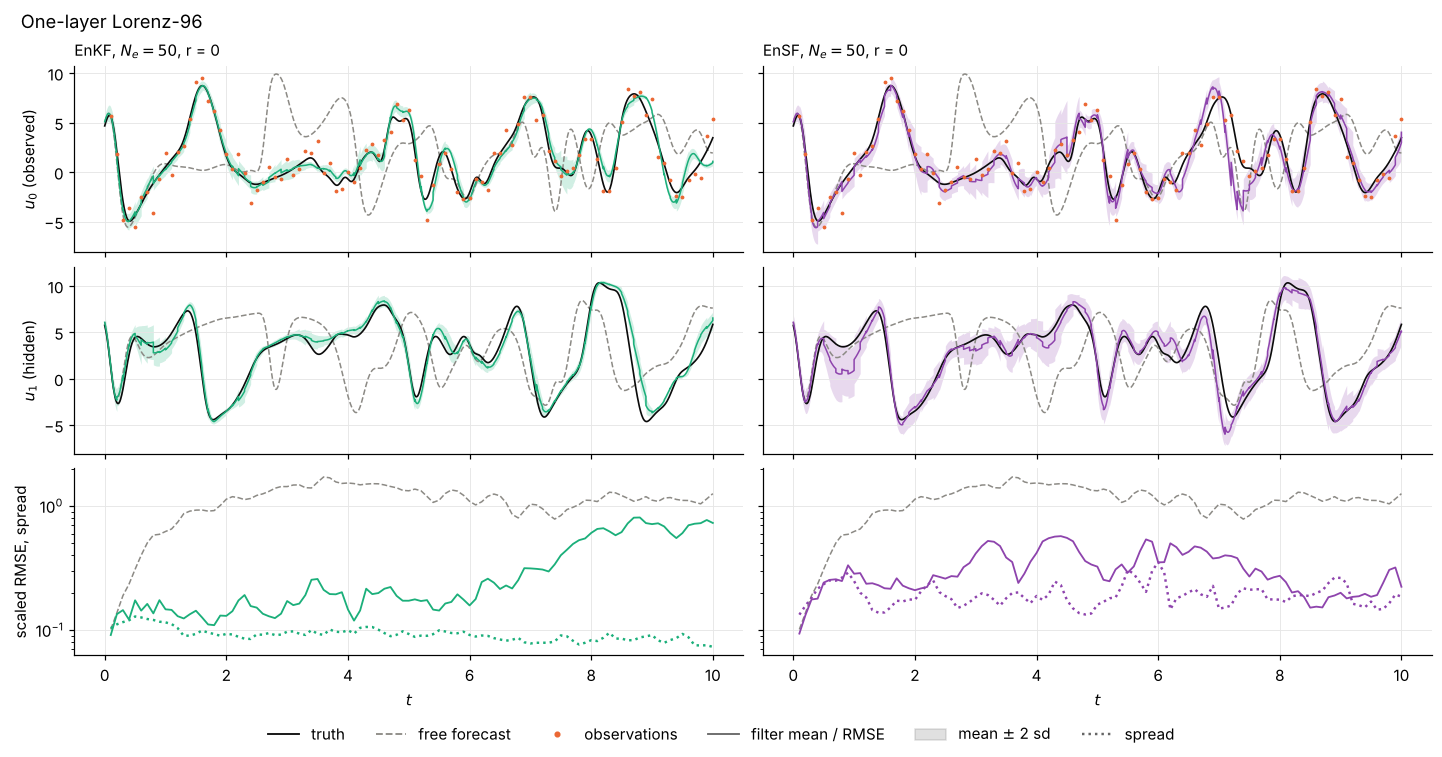

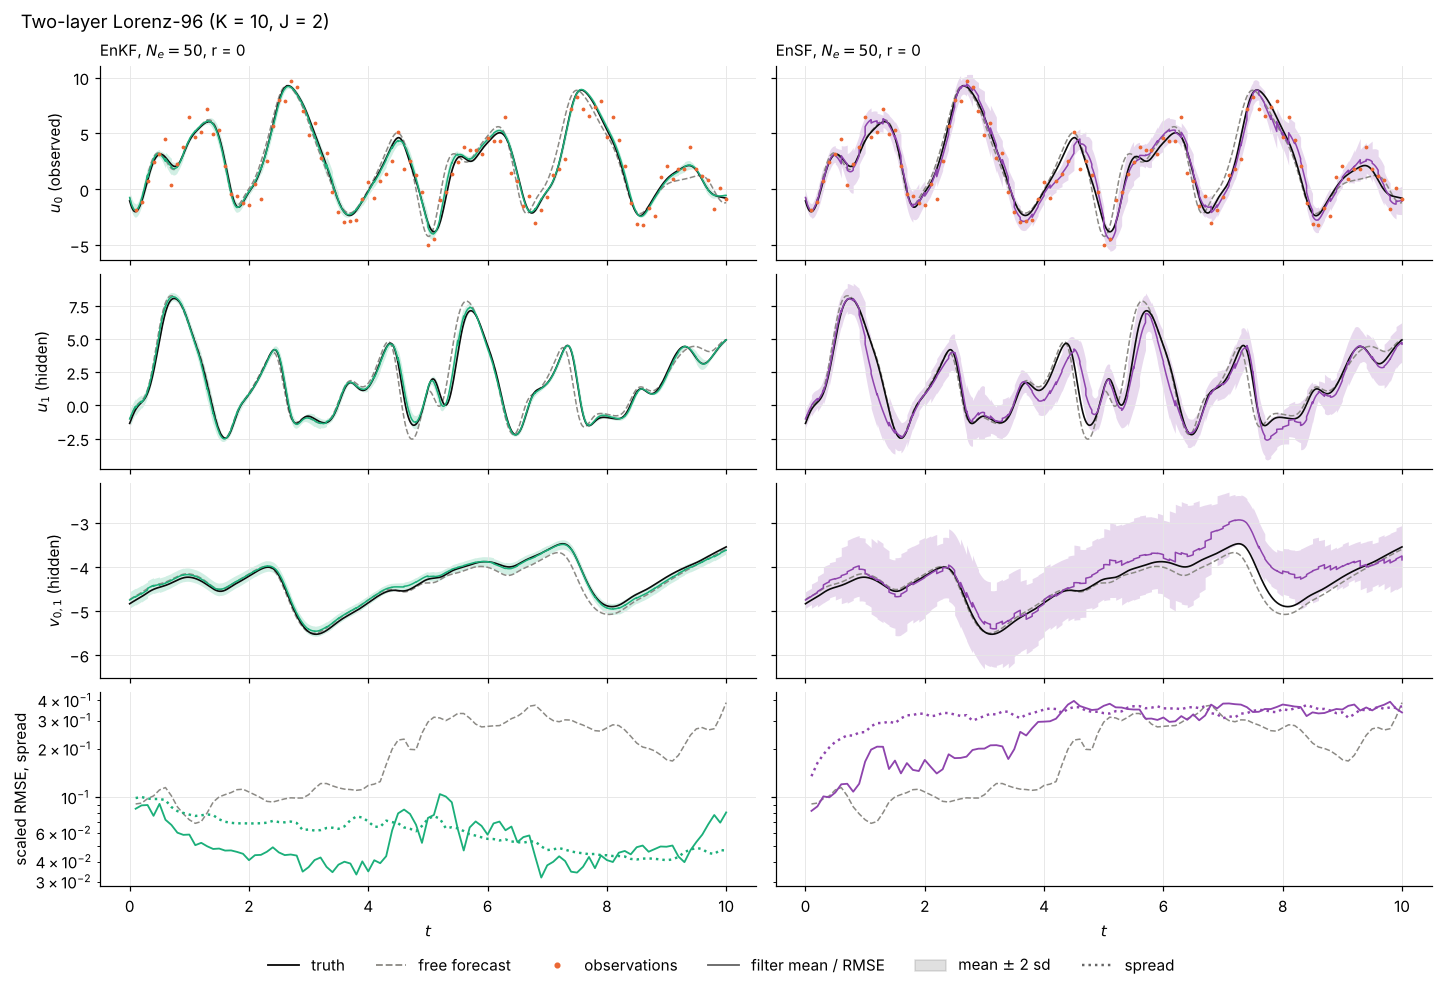

In [7]:
ROWS = {"l96": ["u0", "u1"], "l96_2layer": ["u0", "u1", "v0,1"]}   # observed first, then hidden

def plot_model(name, r=R_SHOW):
    mdl, tw = models[name], twins[name]
    rows = ROWS[name]
    cols = [("EnKF", runs[(name, "enkf", r)], C["enkf"]), ("EnSF", runs[(name, "ensf", r)], C["ensf"])]
    fig, axes = plt.subplots(len(rows) + 1, 2, figsize=(13, 2.1 * len(rows) + 2.6),
                             sharex=True, sharey="row", constrained_layout=True)
    t_tr, X_tr = flatten(tw["truth_segments"], DT)
    t_fr, X_fr = flatten(tw["free_segments"], DT)
    for j, (label, o, color) in enumerate(cols):
        t_m, X_m = flatten(o["seg_mean"], DT, o["mean_a"][-1])
        _, S_m = flatten(o["seg_std"], DT, np.sqrt(np.diag(o["cov_a"][-1])))
        for i, lab in enumerate(rows):
            ax, c = axes[i, j], mdl["labels"].index(lab)
            ax.fill_between(t_m, X_m[:, c] - 2 * S_m[:, c], X_m[:, c] + 2 * S_m[:, c], color=color, alpha=0.2, lw=0)
            ax.plot(t_fr, X_fr[:, c], color=C["free"], ls="--", lw=1)
            ax.plot(t_tr, X_tr[:, c], color=C["truth"], lw=1.1)
            ax.plot(t_m, X_m[:, c], color=color, lw=1)
            if c in mdl["observed"]:
                ax.plot(t_obs, tw["Y"][:, mdl["observed"].index(c)], ".", color=C["obs"], ms=3)
            if j == 0:
                ax.set_ylabel(f"{sym(lab)} ({'observed' if c in mdl['observed'] else 'hidden'})")
        ax = axes[-1, j]
        ax.semilogy(t_obs, free_rmse[name][1:], color=C["free"], ls="--", lw=1)
        ax.semilogy(t_obs, o["rmse"][1:], color=color)
        ax.semilogy(t_obs, o["spread"][1:], color=color, ls=":", lw=1.6)
        ax.set_xlabel("$t$")
        axes[0, j].set_title(f"{label}, $N_e = {NE}$, r = {r}", loc="left", fontsize=10)
    axes[-1, 0].set_ylabel("scaled RMSE, spread")
    handles = [Line2D([], [], color=C["truth"], label="truth"),
               Line2D([], [], color=C["free"], ls="--", label="free forecast"),
               Line2D([], [], color=C["obs"], marker=".", ls="", label="observations"),
               Line2D([], [], color="0.4", label="filter mean / RMSE"),
               Patch(color="0.4", alpha=0.2, label=r"mean $\pm$ 2 sd"),
               Line2D([], [], color="0.4", ls=":", lw=1.6, label="spread")]
    fig.legend(handles=handles, loc="outside lower center", ncol=6)
    fig.suptitle(mdl["title"], x=0.01, ha="left")
    return fig

for name in NAMES:
    plot_model(name)
plt.show()

### RMSE and spread for every replicate

Scaled $\mathrm{RMSE}_k$ (solid) and $\mathrm{Spread}_k$ (dashed); colors are replicates, and the gray line is the free forecast.

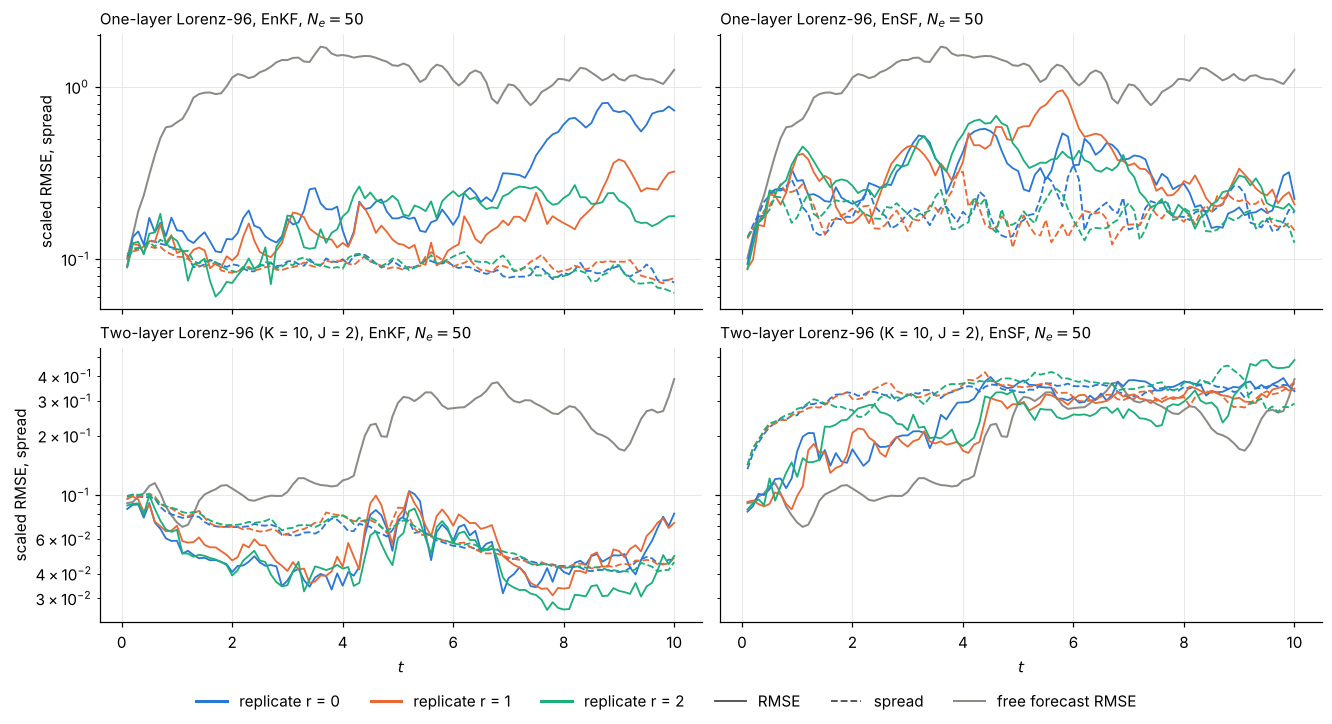

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, sharey="row", constrained_layout=True)
for i, (name, mdl) in enumerate(models.items()):
    for j, flt in enumerate(("enkf", "ensf")):
        ax = axes[i, j]
        ax.semilogy(t_obs, free_rmse[name][1:], color=C["free"], lw=1.3)
        for r, color in zip(REPLICATES, REP_COLORS):
            o = runs[(name, flt, r)]
            ax.semilogy(t_obs, o["rmse"][1:], color=color)
            ax.semilogy(t_obs, o["spread"][1:], color=color, ls="--")
        ax.set_title(f"{mdl['title']}, {FILTER_NAMES[flt]}, $N_e = {NE}$", loc="left", fontsize=10)
    axes[i, 0].set_ylabel("scaled RMSE, spread")
for ax in axes[-1]:
    ax.set_xlabel("$t$")
handles = [Line2D([], [], color=c, lw=2, label=f"replicate r = {r}") for r, c in zip(REPLICATES, REP_COLORS)]
handles += [Line2D([], [], color="0.3", label="RMSE"), Line2D([], [], color="0.3", ls="--", label="spread"),
            Line2D([], [], color=C["free"], lw=1.3, label="free forecast RMSE")]
fig.legend(handles=handles, loc="outside lower center", ncol=6)
plt.show()

### Summary tables

EnKF and EnSF entries are the mean over the three replicates with the range [min, max]. Failed runs would be listed and excluded from the mean and range.

In [9]:
def summary_row(label, results, extra_time=False):
    done = [o for o in results if o["failed_at"] is None]
    failed = [f"k = {o['failed_at']}" for o in results if o["failed_at"] is not None]
    if not done:
        return f"| {label} | — | — | — | — | {len(failed)} of {len(results)} ({', '.join(failed)}) |"
    rt = fmt_range([o["wall_time"] for o in done], 1)
    if extra_time:
        rt += f" (reverse sampling {fmt_range([o['analysis_time'] for o in done], 1)})"
    return (f"| {label} | {fmt_range([time_avg_rmse(o['rmse']) for o in done])} | "
            f"{fmt_range([o['rmse'][-1] for o in done])} | {fmt_range([o['spread'][1:].mean() for o in done])} | "
            f"{rt} | {len(failed)} of {len(results)}{': ' + ', '.join(failed) if failed else ''} |")

for name, mdl in models.items():
    rows = [summary_row(f"EnKF, $N_e = {NE}$", [runs[(name, 'enkf', r)] for r in REPLICATES]),
            summary_row(f"EnSF, $N_e = {NE}$, $L = {L_STEPS}$", [runs[(name, 'ensf', r)] for r in REPLICATES], True)]
    if INCLUDE_EKF:
        o = ekf[name]
        rows.append(f"| EKF (HW 8 settings) | {time_avg_rmse(o['rmse']):.3f} | {o['rmse'][-1]:.3f} | "
                    f"{o['spread'][1:].mean():.3f} | {o['wall_time']:.1f} | {0 if o['failed_at'] is None else 1} of 1 |")
    rows.append(f"| Free forecast | {time_avg_rmse(free_rmse[name]):.3f} | {free_rmse[name][-1]:.3f} | — | — | — |")
    display(Markdown(
        f"**{mdl['title']}** ($n = {mdl['n']}$, $p = {mdl['H'].shape[0]}$)\n\n"
        "| Method | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Failed runs |\n"
        "|---|---|---|---|---|---|\n" + "\n".join(rows)))

**One-layer Lorenz-96** ($n = 40$, $p = 20$)

| Method | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Failed runs |
|---|---|---|---|---|---|
| EnKF, $N_e = 50$ | 0.244 [0.175, 0.371] | 0.410 [0.178, 0.731] | 0.093 [0.093, 0.093] | 0.6 [0.5, 0.7] | 0 of 3 |
| EnSF, $N_e = 50$, $L = 600$ | 0.365 [0.334, 0.409] | 0.208 [0.191, 0.224] | 0.188 [0.183, 0.195] | 7.3 [7.1, 7.5] (reverse sampling 6.7 [6.5, 6.9]) | 0 of 3 |
| EKF (HW 8 settings) | 0.945 | 0.898 | 0.097 | 1.3 | 0 of 1 |
| Free forecast | 1.155 | 1.259 | — | — | — |

**Two-layer Lorenz-96 (K = 10, J = 2)** ($n = 30$, $p = 5$)

| Method | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Failed runs |
|---|---|---|---|---|---|
| EnKF, $N_e = 50$ | 0.056 [0.051, 0.062] | 0.067 [0.049, 0.081] | 0.063 [0.062, 0.064] | 0.6 [0.5, 0.6] | 0 of 3 |
| EnSF, $N_e = 50$, $L = 600$ | 0.276 [0.259, 0.294] | 0.389 [0.337, 0.484] | 0.326 [0.317, 0.333] | 6.7 [6.4, 6.9] (reverse sampling 6.1 [5.8, 6.3]) | 0 of 3 |
| EKF (HW 8 settings) | 0.062 | 0.088 | 0.061 | 1.5 | 0 of 1 |
| Free forecast | 0.220 | 0.388 | — | — | — |

Every run, with its seeds. "Initial ensemble" is shared by the two filters in each row pair; "analysis stream" is the EnKF perturbation stream or the EnSF sampling-noise stream.

In [10]:
rows = []
for name, mdl in models.items():
    m_idx = NAMES.index(name)
    for r in REPLICATES:
        for flt, stream in (("EnKF", 2), ("EnSF", 4)):
            o = runs[(name, flt.lower(), r)]
            status = "completed" if o["failed_at"] is None else f"FAILED k = {o['failed_at']} ({o['message']})"
            rows.append(f"| {mdl['title']} | {flt} | {r} | `[513, 1, {m_idx}, {NE}, {r}]` | `[513, {stream}, {m_idx}, {NE}, {r}]` | "
                        f"{time_avg_rmse(o['rmse']):.3f} | {o['rmse'][-1]:.3f} | {o['spread'][1:].mean():.3f} | "
                        f"{o['wall_time']:.1f} | {status} |")
display(Markdown("| Model | Filter | r | initial ensemble | analysis stream | time-agg. RMSE | final RMSE | "
                 "mean spread | runtime (s) | status |\n|---|---|---|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

| Model | Filter | r | initial ensemble | analysis stream | time-agg. RMSE | final RMSE | mean spread | runtime (s) | status |
|---|---|---|---|---|---|---|---|---|---|
| One-layer Lorenz-96 | EnKF | 0 | `[513, 1, 0, 50, 0]` | `[513, 2, 0, 50, 0]` | 0.371 | 0.731 | 0.093 | 0.7 | completed |
| One-layer Lorenz-96 | EnSF | 0 | `[513, 1, 0, 50, 0]` | `[513, 4, 0, 50, 0]` | 0.334 | 0.224 | 0.195 | 7.4 | completed |
| One-layer Lorenz-96 | EnKF | 1 | `[513, 1, 0, 50, 1]` | `[513, 2, 0, 50, 1]` | 0.175 | 0.323 | 0.093 | 0.6 | completed |
| One-layer Lorenz-96 | EnSF | 1 | `[513, 1, 0, 50, 1]` | `[513, 4, 0, 50, 1]` | 0.409 | 0.208 | 0.185 | 7.5 | completed |
| One-layer Lorenz-96 | EnKF | 2 | `[513, 1, 0, 50, 2]` | `[513, 2, 0, 50, 2]` | 0.185 | 0.178 | 0.093 | 0.5 | completed |
| One-layer Lorenz-96 | EnSF | 2 | `[513, 1, 0, 50, 2]` | `[513, 4, 0, 50, 2]` | 0.351 | 0.191 | 0.183 | 7.1 | completed |
| Two-layer Lorenz-96 (K = 10, J = 2) | EnKF | 0 | `[513, 1, 1, 50, 0]` | `[513, 2, 1, 50, 0]` | 0.057 | 0.081 | 0.062 | 0.6 | completed |
| Two-layer Lorenz-96 (K = 10, J = 2) | EnSF | 0 | `[513, 1, 1, 50, 0]` | `[513, 4, 1, 50, 0]` | 0.294 | 0.337 | 0.327 | 6.4 | completed |
| Two-layer Lorenz-96 (K = 10, J = 2) | EnKF | 1 | `[513, 1, 1, 50, 1]` | `[513, 2, 1, 50, 1]` | 0.062 | 0.072 | 0.064 | 0.5 | completed |
| Two-layer Lorenz-96 (K = 10, J = 2) | EnSF | 1 | `[513, 1, 1, 50, 1]` | `[513, 4, 1, 50, 1]` | 0.259 | 0.347 | 0.317 | 6.9 | completed |
| Two-layer Lorenz-96 (K = 10, J = 2) | EnKF | 2 | `[513, 1, 1, 50, 2]` | `[513, 2, 1, 50, 2]` | 0.051 | 0.049 | 0.064 | 0.6 | completed |
| Two-layer Lorenz-96 (K = 10, J = 2) | EnSF | 2 | `[513, 1, 1, 50, 2]` | `[513, 4, 1, 50, 2]` | 0.274 | 0.484 | 0.333 | 6.9 | completed |

Error and spread by component group: time-aggregated RMSE / RMS spread over $k = 1, \dots, L$ for the observed and hidden components (and each variable family of the two-layer model), averaged over the three replicates.

In [11]:
def group_errors(o, mdl, tw, idx):
    err = (o["mean_a"][1:, idx] - tw["x_true"][1:, idx]) / mdl["D"][idx]
    sd = np.sqrt(np.diagonal(o["cov_a"][1:], axis1=1, axis2=2)[:, idx]) / mdl["D"][idx]
    return np.sqrt(np.mean(err ** 2)), np.sqrt(np.mean(sd ** 2))

for name, mdl in models.items():
    tw = twins[name]
    obs = np.array(mdl["observed"])
    hid = np.setdiff1d(np.arange(mdl["n"]), obs)
    groups = {"observed": obs, "hidden": hid}
    if mdl["J"]:
        fam = hw8.variable_families(name)
        groups.update({"hidden u": np.intersect1d(fam["u"], hid), "v1 (hidden)": fam["v1"], "v2 (hidden)": fam["v2"]})
    rows = []
    for flt in ("enkf", "ensf"):
        vals = [np.mean([group_errors(runs[(name, flt, r)], mdl, tw, idx) for r in REPLICATES
                         if runs[(name, flt, r)]["failed_at"] is None], axis=0) for idx in groups.values()]
        rows.append(f"| {'EnKF' if flt == 'enkf' else 'EnSF'} | " + " | ".join(f"{e:.3f} / {s:.3f}" for e, s in vals) + " |")
    display(Markdown(f"**{mdl['title']}**\n\n| Filter | " + " | ".join(groups) + " |\n|" + "---|" * (len(groups) + 1)
                     + "\n" + "\n".join(rows)))

**One-layer Lorenz-96**

| Filter | observed | hidden |
|---|---|---|
| EnKF | 0.225 / 0.089 | 0.261 / 0.098 |
| EnSF | 0.277 / 0.152 | 0.435 / 0.224 |

**Two-layer Lorenz-96 (K = 10, J = 2)**

| Filter | observed | hidden | hidden u | v1 (hidden) | v2 (hidden) |
|---|---|---|---|---|---|
| EnKF | 0.061 / 0.066 | 0.056 / 0.065 | 0.064 / 0.068 | 0.054 / 0.068 | 0.052 / 0.060 |
| EnSF | 0.184 / 0.196 | 0.290 / 0.350 | 0.216 / 0.274 | 0.340 / 0.391 | 0.266 / 0.341 |

**Comments on (c).** *Compare the two filters on both models: error, spread, variability across seeds, cost, and any failures.*



## (d) Numerical sensitivity

One model and one change (`SENS`), with all other settings, the saved data, and the seed streams fixed. The default is the one-layer model with $N_e = 200$: EnKF and EnSF are both rerun at $N_e = 200$ with replicates $r = 0, 1, 2$ (initial ensembles `[513, 1, 0, 200, r]`, the same ensembles as the HW 8 $N_e = 200$ runs, shared by the two filters) and compared with the $N_e = 50$ baseline from (c). Setting `SENS = dict(model="l96", kind="L", value=...)` instead reruns only EnSF with a different number of reverse steps. The cost of one EnSF analysis grows roughly like $L N_e^2 n$.

**One-layer Lorenz-96**: change Ne to 200

| Configuration | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Failed runs | distinct dominant members / $N_e$ |
|---|---|---|---|---|---|---|
| EnKF, $N_e = 50$ | 0.244 [0.175, 0.371] | 0.410 [0.178, 0.731] | 0.093 [0.093, 0.093] | 0.6 [0.5, 0.7] | 0 of 3 | — |
| EnKF, $N_e = 200$ | 0.111 [0.109, 0.115] | 0.082 [0.072, 0.092] | 0.104 [0.103, 0.104] | 1.3 [1.2, 1.3] | 0 of 3 | — |
| EnSF, $N_e = 50$ | 0.365 [0.334, 0.409] | 0.208 [0.191, 0.224] | 0.188 [0.183, 0.195] | 7.3 [7.1, 7.5] (reverse sampling 6.7 [6.5, 6.9]) | 0 of 3 | 0.32 [0.31, 0.33] |
| EnSF, $N_e = 200$ | 0.291 [0.252, 0.319] | 0.222 [0.181, 0.255] | 0.210 [0.209, 0.210] | 49.5 [48.6, 51.1] (reverse sampling 48.3 [47.4, 49.8]) | 0 of 3 | 0.28 [0.27, 0.29] |

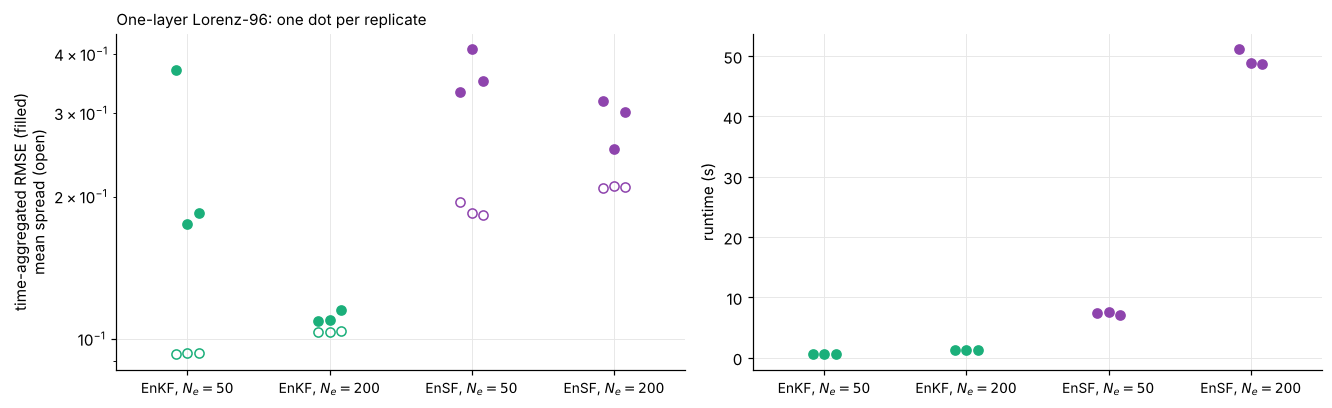

In [12]:
SENS = dict(model="l96", kind="Ne", value=200)      # or dict(model="l96", kind="L", value=150)

s_name, s_mdl, s_tw = SENS["model"], models[SENS["model"]], twins[SENS["model"]]
sens = {}
for r in REPLICATES:
    if SENS["kind"] == "Ne":
        out = run_filters(s_mdl, s_tw, SENS["value"], r)
    else:
        out = run_filters(s_mdl, s_tw, NE, r, L=SENS["value"], enkf=False)
    for flt, o in out.items():
        sens[(flt, r)] = o

if SENS["kind"] == "Ne":
    configs = [(f"EnKF, $N_e = {NE}$", [runs[(s_name, "enkf", r)] for r in REPLICATES], C["enkf"]),
               (f"EnKF, $N_e = {SENS['value']}$", [sens[("enkf", r)] for r in REPLICATES], C["enkf"]),
               (f"EnSF, $N_e = {NE}$", [runs[(s_name, "ensf", r)] for r in REPLICATES], C["ensf"]),
               (f"EnSF, $N_e = {SENS['value']}$", [sens[("ensf", r)] for r in REPLICATES], C["ensf"])]
else:
    configs = [(f"EnSF, $L = {L_STEPS}$", [runs[(s_name, "ensf", r)] for r in REPLICATES], C["ensf"]),
               (f"EnSF, $L = {SENS['value']}$", [sens[("ensf", r)] for r in REPLICATES], C["ensf"])]

rows = []
for label, res, _ in configs:
    row = summary_row(label, res, extra_time=label.startswith("EnSF"))
    if label.startswith("EnSF"):
        Ne_used = res[0]["E_a"].shape[2]
        row += f" {fmt_range([np.nanmean(o['n_distinct']) / Ne_used for o in res], 2)} |"
    else:
        row += " — |"
    rows.append(row)
display(Markdown(
    f"**{s_mdl['title']}**: change {SENS['kind']} to {SENS['value']}\n\n"
    "| Configuration | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Failed runs | "
    "distinct dominant members / $N_e$ |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
x = np.arange(len(configs))
for xi, (label, res, color) in zip(x, configs):
    for r, o in zip(REPLICATES, res):
        if o["failed_at"] is not None:
            continue
        jitter = (r - 1) * 0.08
        axes[0].plot(xi + jitter, time_avg_rmse(o["rmse"]), "o", color=color, ms=6)
        axes[0].plot(xi + jitter, o["spread"][1:].mean(), "o", mfc="none", color=color, ms=6)
        axes[1].plot(xi + jitter, o["wall_time"], "o", color=color, ms=6)
for ax in axes:
    ax.set_xticks(x, [lab for lab, _, _ in configs], fontsize=9)
    ax.set_xlim(-0.5, len(configs) - 0.5)
axes[0].set_yscale("log")
axes[0].set_ylabel("time-aggregated RMSE (filled)\nmean spread (open)")
axes[1].set_ylabel("runtime (s)")
axes[0].set_title(f"{s_mdl['title']}: one dot per replicate", loc="left", fontsize=10)
plt.show()

**Answer to (d).** *Compare error, spread, and cost with the baseline. Explain which errors the change can reduce and which remain, including the guided-score and endpoint approximations.*



## (e) Supporting diagnostics

### How the terminal weights select forecast members

At the last reverse step ($\tau = \Delta\tau$), each analysis sample's local weights $\rho_i$ are recorded. Their effective sample size $1/\sum_i\rho_i^2$ shows how many forecast clouds still contribute at a sample, and the number of **distinct** forecast members that dominate (largest $\rho_i$) across the $N_e$ samples shows how many forecast members the analysis ensemble is effectively built from.

One-layer Lorenz-96: terminal effective sample size per analysis sample: mean 1.004, max 2.76;  distinct dominant members: mean 15.9 of 50
Two-layer Lorenz-96 (K = 10, J = 2): terminal effective sample size per analysis sample: mean 1.005, max 2.39;  distinct dominant members: mean 28.5 of 50


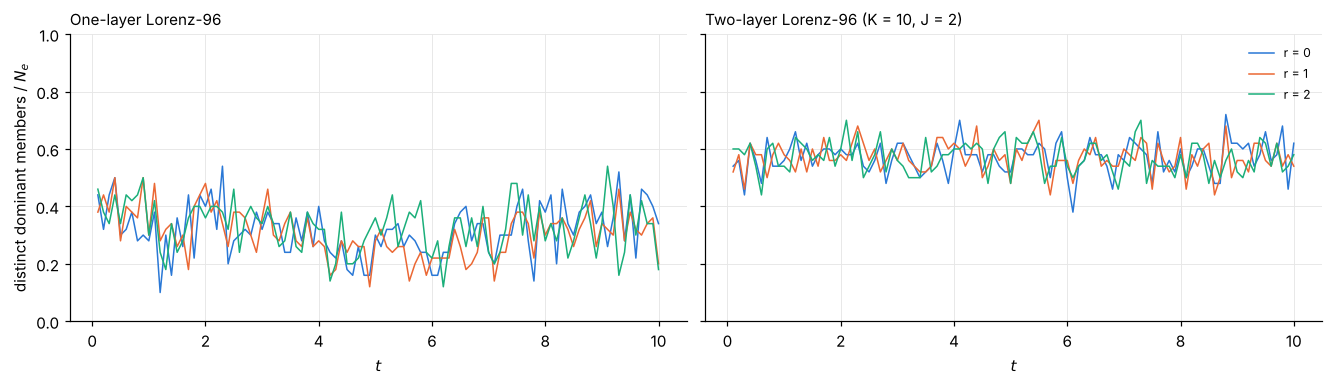

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True, constrained_layout=True)
for ax, (name, mdl) in zip(axes, models.items()):
    for r, color in zip(REPLICATES, REP_COLORS):
        o = runs[(name, "ensf", r)]
        ax.plot(t_obs, o["n_distinct"] / NE, color=color, lw=1, label=f"r = {r}")
    ess = np.concatenate([runs[(name, "ensf", r)]["ess"].ravel() for r in REPLICATES])
    print(f"{mdl['title']}: terminal effective sample size per analysis sample: mean {np.nanmean(ess):.3f}, "
          f"max {np.nanmax(ess):.2f};  distinct dominant members: mean "
          f"{np.nanmean([runs[(name, 'ensf', r)]['n_distinct'] for r in REPLICATES]):.1f} of {NE}")
    ax.set_title(mdl["title"], loc="left", fontsize=10)
    ax.set_xlabel("$t$")
axes[0].set_ylabel(r"distinct dominant members / $N_e$")
axes[0].set_ylim(0, 1)
axes[1].legend(fontsize=8)
plt.show()

### Reverse-sampling paths at one analysis

Replicate `R_SHOW`, analysis `K_SHOW`: 12 of the $N_e$ sampler positions (colored) plotted against artificial time, in physical units ($c + Dz$), for an observed and a hidden coordinate. Gray lines are the moving cloud centers $c + D\,a_\tau u_k^{f,(i)}$ of all forecast members; the black star is the truth at $t_k$ and the orange marker the observation. Artificial time runs from $\tau = 1$ (left) to $\tau = 0$ (right).

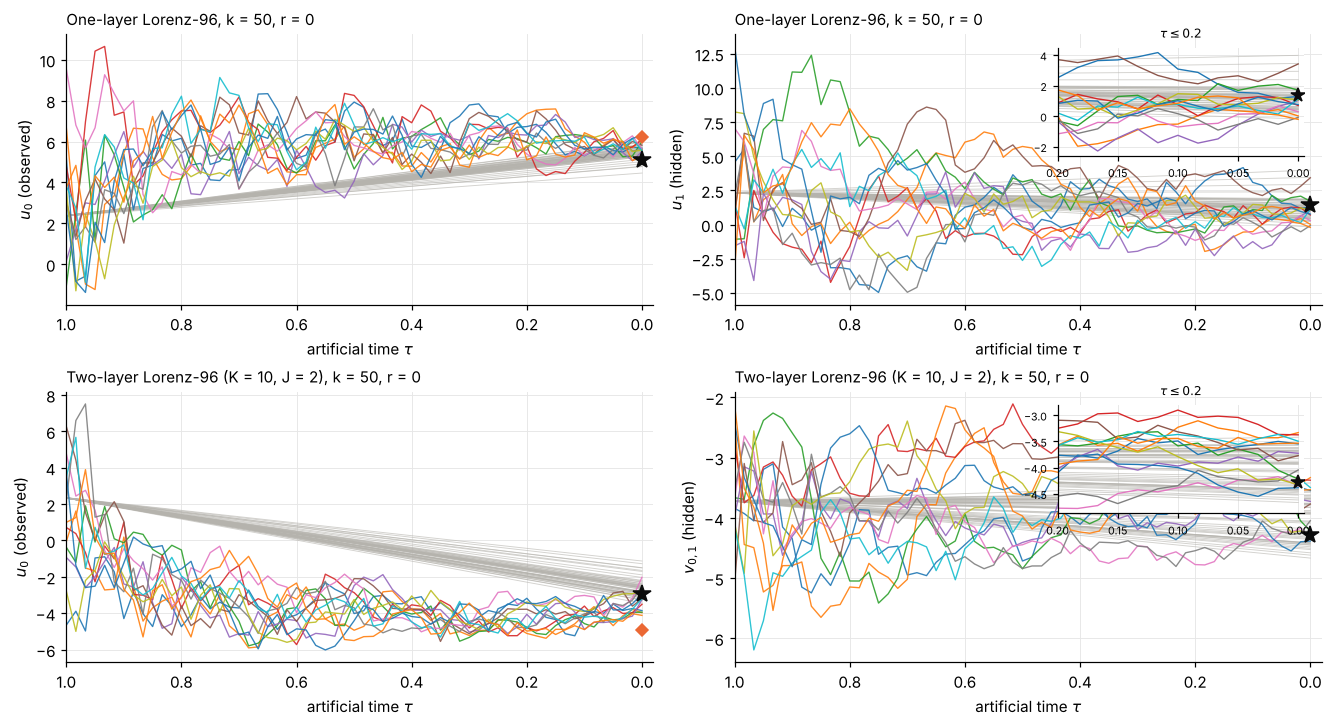

In [14]:
PATH_ROWS = {"l96": ["u0", "u1"], "l96_2layer": ["u0", "v0,1"]}
N_PATHS = 12

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), constrained_layout=True)
for i, (name, mdl) in enumerate(models.items()):
    o, tw = runs[(name, "ensf", R_SHOW)], twins[name]
    P = o["paths"]
    k, taus, path = P["k"], P["taus"], P["path"]            # path: (n_rec, n, Ne), physical units
    a_tau = schedule(taus, EPS_A, EPS_B[name])[0]
    UF = hw9.to_u(o["E_f"][k], mdl)
    for j, lab in enumerate(PATH_ROWS[name]):
        ax, c = axes[i, j], mdl["labels"].index(lab)
        centers = mdl["c"][c] + mdl["D"][c] * a_tau[:, None] * UF[c][None, :]
        ax.plot(taus, centers, color=C["fc"], lw=0.6, alpha=0.6)
        for s in range(N_PATHS):
            ax.plot(taus, path[:, c, s], lw=0.9, alpha=0.9)
        ax.plot(0, tw["x_true"][k, c], "*", color=C["truth"], ms=12, zorder=5)
        if c in mdl["observed"]:
            ax.plot(0, tw["Y"][k - 1, mdl["observed"].index(c)], "D", color=C["obs"], ms=6, zorder=5)
        ax.set_xlim(1.0, -0.02)
        ax.set_xlabel(r"artificial time $\tau$")
        ax.set_ylabel(f"{sym(lab)} ({'observed' if c in mdl['observed'] else 'hidden'})")
        ax.set_title(f"{mdl['title']}, k = {k}, r = {R_SHOW}", loc="left", fontsize=10)
    # zoom: the last 20% of artificial time
    ins = axes[i, 1].inset_axes([0.55, 0.55, 0.42, 0.4])
    c = mdl["labels"].index(PATH_ROWS[name][1])
    keep = taus <= 0.2
    centers = mdl["c"][c] + mdl["D"][c] * a_tau[keep, None] * UF[c][None, :]
    ins.plot(taus[keep], centers, color=C["fc"], lw=0.6, alpha=0.6)
    for s in range(N_PATHS):
        ins.plot(taus[keep], path[keep, c, s], lw=0.9)
    ins.plot(0, tw["x_true"][k, c], "*", color=C["truth"], ms=9)
    ins.set_xlim(0.2, -0.005)
    ins.tick_params(labelsize=7)
    ins.set_title(r"$\tau \leq 0.2$", fontsize=8)
plt.show()

### One analysis, same forecast ensemble, two analysis rules

To separate the analysis rule from the different forecasts the two filters produce, the EnSF forecast ensemble at `K_SHOW` (replicate `R_SHOW`) is analyzed both ways: the EnSF analysis is the one the run produced, and an EnKF analysis of the **same** forecast members uses a separate perturbation stream (`hw9.rng_compare`, `[513, 5, model, Ne, r]`). Each panel plots a hidden coordinate against the observed coordinate whose forecast correlation with it is largest in magnitude. The table lists the hidden coordinate's truth, means, and standard deviations.

One-layer Lorenz-96, k = 50: the EnSF analysis members are dominated (terminal weights) by 15 distinct forecast members of 50
Two-layer Lorenz-96 (K = 10, J = 2), k = 50: the EnSF analysis members are dominated (terminal weights) by 26 distinct forecast members of 50


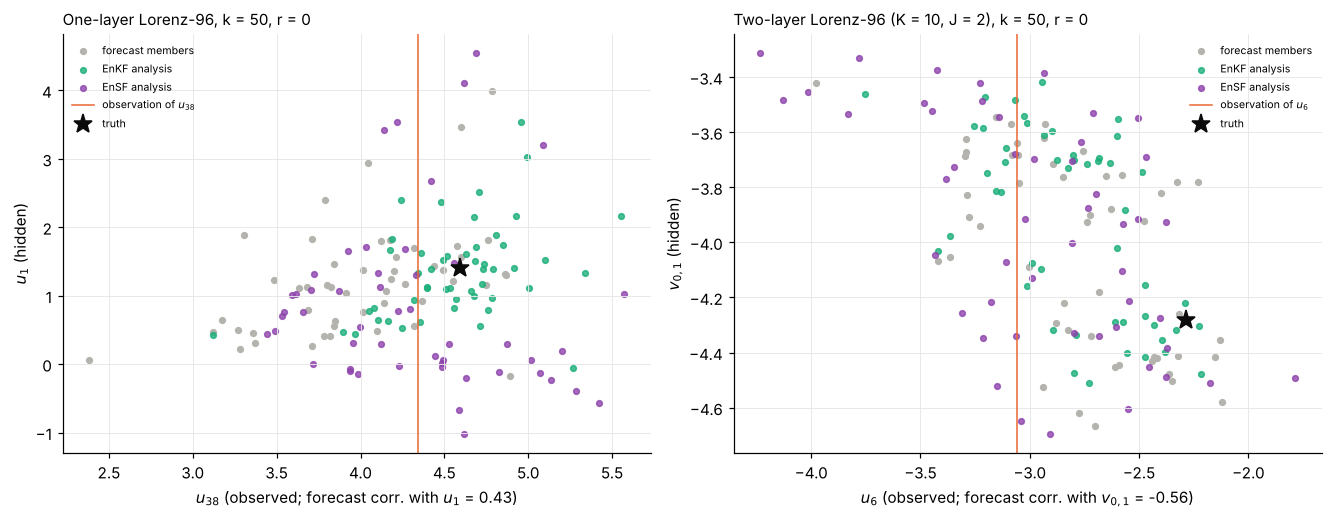

| Model | hidden coordinate | ensemble | mean | sd | truth |
|---|---|---|---|---|---|
| One-layer Lorenz-96 | u1 | forecast | 1.1976 | 0.8023 | 1.4040 |
| One-layer Lorenz-96 | u1 | EnKF analysis | 1.3462 | 0.6963 | 1.4040 |
| One-layer Lorenz-96 | u1 | EnSF analysis | 0.8295 | 1.2248 | 1.4040 |
| Two-layer Lorenz-96 (K = 10, J = 2) | v0,1 | forecast | -4.0278 | 0.3532 | -4.2803 |
| Two-layer Lorenz-96 (K = 10, J = 2) | v0,1 | EnKF analysis | -3.9333 | 0.3398 | -4.2803 |
| Two-layer Lorenz-96 (K = 10, J = 2) | v0,1 | EnSF analysis | -3.9499 | 0.4097 | -4.2803 |

In [15]:
HIDDEN = {"l96": "u1", "l96_2layer": "v0,1"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
rows = []
for ax, (name, mdl) in zip(axes, models.items()):
    o, tw = runs[(name, "ensf", R_SHOW)], twins[name]
    k, h = K_SHOW, mdl["labels"].index(HIDDEN[name])
    Ef, Ea_sf = o["E_f"][k], o["E_a"][k]
    Ea_kf, _ = enkf_analysis(Ef, tw["Y"][k - 1], mdl["H"], mdl["R"], hw9.rng_compare(name, NE, R_SHOW))
    obs = mdl["observed"]
    corr = [np.corrcoef(Ef[h], Ef[j])[0, 1] for j in obs]
    jo = obs[int(np.argmax(np.abs(corr)))]
    ax.scatter(Ef[jo], Ef[h], s=14, color=C["fc"], label="forecast members")
    ax.scatter(Ea_kf[jo], Ea_kf[h], s=14, color=C["enkf"], alpha=0.8, label="EnKF analysis")
    ax.scatter(Ea_sf[jo], Ea_sf[h], s=14, color=C["ensf"], alpha=0.8, label="EnSF analysis")
    ax.axvline(tw["Y"][k - 1][obs.index(jo)], color=C["obs"], lw=1, label=f"observation of {sym(mdl['labels'][jo])}")
    ax.plot(tw["x_true"][k, jo], tw["x_true"][k, h], "*", color=C["truth"], ms=13, label="truth")
    ax.set_xlabel(f"{sym(mdl['labels'][jo])} (observed; forecast corr. with {sym(HIDDEN[name])} = {corr[obs.index(jo)]:.2f})")
    ax.set_ylabel(f"{sym(HIDDEN[name])} (hidden)")
    ax.set_title(f"{mdl['title']}, k = {k}, r = {R_SHOW}", loc="left", fontsize=10)
    ax.legend(fontsize=7)
    for lab, E in (("forecast", Ef), ("EnKF analysis", Ea_kf), ("EnSF analysis", Ea_sf)):
        rows.append(f"| {mdl['title']} | {HIDDEN[name]} | {lab} | {E[h].mean():.4f} | {E[h].std(ddof=1):.4f} | "
                    f"{tw['x_true'][k, h]:.4f} |")
    print(f"{mdl['title']}, k = {k}: the EnSF analysis members are dominated (terminal weights) by "
          f"{int(o['n_distinct'][k - 1])} distinct forecast members of {NE}")
plt.show()
display(Markdown("| Model | hidden coordinate | ensemble | mean | sd | truth |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(rows)))

**Answer to (e).** *Explain why reverse-sampling noise is needed despite $Q_{k-1} = 0$. For one model, discuss the analysis of a hidden coordinate. Summarize when EnSF is useful or problematic, and identify any failed runs.*



## AI use (draft — edit as needed)

Claude (Anthropic) helped write and debug the code for Problem 3: the `ensf.py` module (schedule, mixture and likelihood scores, reverse sampler, EnSF cycling with failure records), the `hw9.py` settings module, and the code cells in this notebook (checks, runs, figures, and tables). I checked the code against Section 3 of the diffusion notes. The numerical-choice justification and the written answers to (c)–(e) are my own, and Problems 1–2 were completed without AI.